# 04 · Calendar-aging fit (Stage 1, full factorial)

First parametric fit for the thesis. Fits a calendar-aging model to the Stage-1 full-factorial (FF) calendar arm and compares two uncertainty estimates for its parameters: Fisher (Gauss–Newton) standard errors and a cell-level cluster bootstrap. This is the first C2 data point.

**Model** (`src/calendar_model.py`):

$$Q_{\mathrm{rel}}(t) = 1 - k(T,\mathrm{SoC})\,(t^{z} - t_0^{z}), \qquad \log k = \log k_{\mathrm{ref}} - \frac{E_a}{R}\Big(\frac{1}{T}-\frac{1}{T_{\mathrm{ref}}}\Big) + c_{\mathrm{SoC}}(\mathrm{SoC}-0.5)$$

$Q_{\mathrm{rel}}$ is normalized to each cell's first regular check-up at $t_0$; $T_{\mathrm{ref}} = 23\,^{\circ}$C; $t$ in years.

**Data scope.** Of the 66 Stage-1 calendar cells, 33 have only entry and end tests (no regular check-ups) and are excluded here; the fit uses the 33 cells with regular CU/exCU check-ups (3 per condition, 11 conditions).

In [1]:
# Load Stage-1 FF calendar check-ups
import sys
sys.path.insert(0, "../src")
import numpy as np
import pandas as pd
from calendar_model import load_calendar

PARQUET = "../data/processed/capacity_rpt.parquet"
d = load_calendar(PARQUET, stage=1, sampling="FF")
print(f"rows: {len(d)} | cells: {d['cell_id'].nunique()} | conditions: {d['cond'].nunique()}")
d.groupby("cond").agg(cells=("cell_id", "nunique"), checkups=("Q_rel", "size"),
                      max_days=("days", "max"), min_Q_rel=("Q_rel", "min"))

rows: 165 | cells: 33 | conditions: 11


,cells,checkups,max_days,min_Q_rel
cond,,,,
10C/0.05,3,18,349.0,0.992336
10C/0.50,3,18,349.0,0.987721
10C/1.00,3,18,341.0,0.978936
23C/0.05,3,12,285.0,0.994796
23C/0.50,3,12,285.0,0.987283
23C/1.00,3,12,285.0,0.979564
45C/0.05,3,15,304.0,0.991067
45C/0.20,3,15,306.0,0.983868
45C/0.50,3,15,306.0,0.963648


In [2]:
# Fit parametric model (4 parameters) and saturated model (free rate per condition, shared z)
import sys
sys.path.insert(0, "../src")
import numpy as np
import pandas as pd
from calendar_model import load_calendar, fit, predict_param, predict_saturated, PARAM_NAMES

d = load_calendar("../data/processed/capacity_rpt.parquet", stage=1, sampling="FF")
conds = sorted(d["cond"].unique())

fp = fit(predict_param, d, np.array([np.log(0.02), 30.0, 1.0, 0.6]))
fs = fit(predict_saturated, d, np.r_[np.full(len(conds), np.log(0.02)), 0.6], conds=conds)

se = np.sqrt(np.diag(fp["cov"]))
print(pd.DataFrame({"estimate": fp["theta"], "Fisher SE": se}, index=PARAM_NAMES).round(4))
print(f"\nresidual SD (parametric): {np.sqrt(fp['rss'] / (fp['n'] - fp['p'])):.5f}")
print(f"residual SD (saturated):  {np.sqrt(fs['rss'] / (fs['n'] - fs['p'])):.5f}")

# Lack-of-fit F-test: parametric (nested) vs saturated condition effects
from scipy import stats
df1, df2 = fs["p"] - fp["p"], fs["n"] - fs["p"]
F = ((fp["rss"] - fs["rss"]) / df1) / (fs["rss"] / df2)
print(f"lack-of-fit F({df1}, {df2}) = {F:.1f}, p = {stats.f.sf(F, df1, df2):.2e}")

           estimate  Fisher SE
log_k_ref   -3.8891     0.0417
Ea_kJ       24.8698     1.2458
c_soc        1.2533     0.0641
z            0.7896     0.0939

residual SD (parametric): 0.00378
residual SD (saturated):  0.00155
lack-of-fit F(8, 153) = 100.5, p = 5.87e-57


In [3]:
# Per-condition residual bias of the parametric model
import sys
sys.path.insert(0, "../src")
import numpy as np
import pandas as pd
from calendar_model import load_calendar, fit, predict_param

d = load_calendar("../data/processed/capacity_rpt.parquet", stage=1, sampling="FF")
fp = fit(predict_param, d, np.array([np.log(0.02), 30.0, 1.0, 0.6]))
d["resid"] = fp["resid"]                                    # predicted minus observed
(d.groupby("cond")["resid"].agg(["mean", "std", "size"]) * [100, 100, 1]).round(3).rename(
    columns={"mean": "mean resid (% Q0)", "std": "SD (% Q0)", "size": "n"})

,mean resid (% Q0),SD (% Q0),n
cond,,,
10C/0.05,0.078,0.117,18
10C/0.50,0.083,0.100,18
10C/1.00,0.170,0.098,18
23C/0.05,-0.347,0.228,12
23C/0.50,-0.059,0.046,12
23C/1.00,-0.232,0.238,12
45C/0.05,-0.403,0.250,15
45C/0.20,-0.172,0.117,15
45C/0.50,0.451,0.230,15


In [4]:
# Fisher vs cell-level cluster bootstrap standard errors (B = 1000)
import sys
sys.path.insert(0, "../src")
import numpy as np
import pandas as pd
from calendar_model import load_calendar, fit, predict_param, cluster_bootstrap, PARAM_NAMES

d = load_calendar("../data/processed/capacity_rpt.parquet", stage=1, sampling="FF")
fp = fit(predict_param, d, np.array([np.log(0.02), 30.0, 1.0, 0.6]))
draws = cluster_bootstrap(predict_param, d, fp["theta"], B=1000, seed=0)

se_fisher = np.sqrt(np.diag(fp["cov"]))
se_boot = draws.std(axis=0, ddof=1)
lo, hi = np.percentile(draws, [2.5, 97.5], axis=0)
tab = pd.DataFrame({"estimate": fp["theta"], "Fisher SE": se_fisher, "bootstrap SE": se_boot,
                    "ratio boot/Fisher": se_boot / se_fisher,
                    "Wald 95% lo": fp["theta"] - 1.96 * se_fisher, "Wald 95% hi": fp["theta"] + 1.96 * se_fisher,
                    "pct 95% lo": lo, "pct 95% hi": hi}, index=PARAM_NAMES)
np.save("../data/processed/calendar_s1_boot.npy", draws)
tab.round(4)

,estimate,Fisher SE,bootstrap SE,ratio boot/Fisher,Wald 95% lo,Wald 95% hi,pct 95% lo,pct 95% hi
log_k_ref,-3.8891,0.0417,0.0166,0.3973,-3.9709,-3.8074,-3.9240,-3.8587
Ea_kJ,24.8698,1.2458,0.4647,0.3730,22.4281,27.3115,23.9427,25.7926
c_soc,1.2533,0.0641,0.0249,0.3886,1.1275,1.3790,1.2032,1.3023
z,0.7896,0.0939,0.0195,0.2080,0.6056,0.9737,0.7523,0.8287


**Caveats for interpretation.**
- Fisher SEs assume independent, homoscedastic residuals and a correct model. Repeated check-ups on the same cell are correlated, and the lack-of-fit test above indicates the parametric SoC/temperature form is misspecified; the pooled residual variance therefore absorbs model discrepancy.
- The cluster bootstrap resamples only 3 cells per condition, so it has few distinct resamples and is biased low by roughly $\sqrt{(n-1)/n}$ per condition. Neither SE is a reliable benchmark on its own; this motivates the C2 simulation study, where the truth is known.

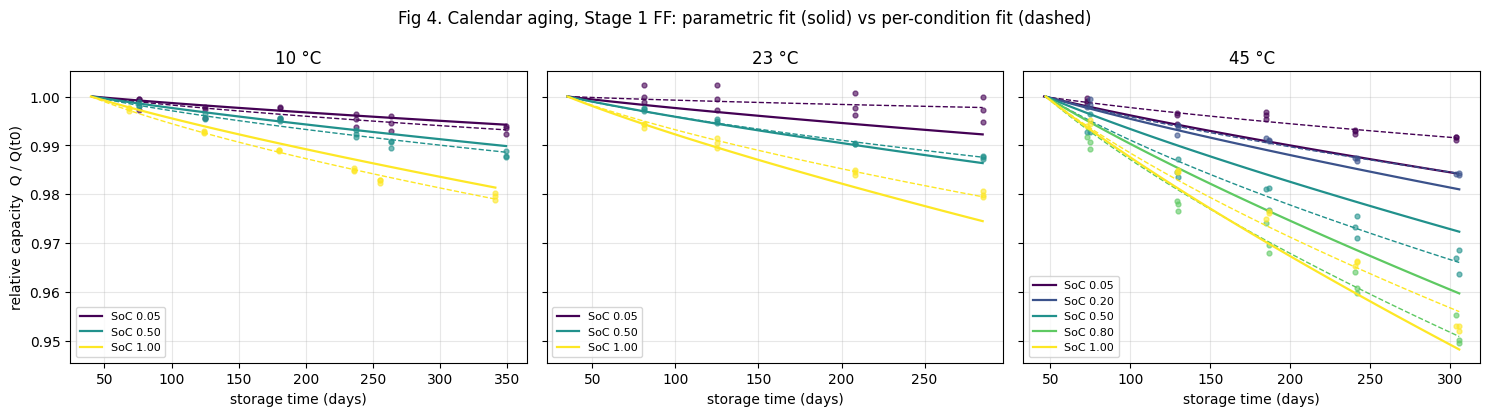

In [5]:
# Fig 4: Stage-1 calendar data with parametric (solid) and saturated (dashed) fits
import sys
sys.path.insert(0, "../src")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from calendar_model import load_calendar, fit, predict_param, predict_saturated

d = load_calendar("../data/processed/capacity_rpt.parquet", stage=1, sampling="FF")
conds = sorted(d["cond"].unique())
fp = fit(predict_param, d, np.array([np.log(0.02), 30.0, 1.0, 0.6]))
fs = fit(predict_saturated, d, np.r_[np.full(len(conds), np.log(0.02)), 0.6], conds=conds)

socs = sorted(d["soc"].unique())
cmap = plt.get_cmap("viridis")
colors = {s: cmap(i / (len(socs) - 1)) for i, s in enumerate(socs)}
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2), sharey=True)
for ax, T in zip(axes, sorted(d["amb_temp_tp"].unique())):
    dT = d[d["amb_temp_tp"] == T]
    for s, g in dT.groupby("soc"):
        for _, cg in g.groupby("cell_id"):
            ax.plot(cg["days"], cg["Q_rel"], "o", ms=3.5, color=colors[s], alpha=0.6)
        t0 = g["t0"].median()
        grid = pd.DataFrame({"t": np.linspace(t0, g["t"].max(), 100)})
        grid = grid.assign(t0=t0, T_K=T + 273.15, soc=s, cond=g["cond"].iloc[0])
        ax.plot(grid["t"] * 365.25, predict_param(fp["theta"], grid), "-", color=colors[s], lw=1.6,
                label=f"SoC {s:.2f}")
        ax.plot(grid["t"] * 365.25, predict_saturated(fs["theta"], grid, conds), "--", color=colors[s], lw=1)
    ax.set_title(f"{T} °C")
    ax.set_xlabel("storage time (days)")
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8, loc="lower left")
axes[0].set_ylabel("relative capacity  Q / Q(t0)")
fig.suptitle("Fig 4. Calendar aging, Stage 1 FF: parametric fit (solid) vs per-condition fit (dashed)")
fig.tight_layout()
fig.savefig("../figs/fig4_calendar_fit.png", dpi=200, bbox_inches="tight")
plt.show()

## Next
- Replace the log-linear SoC term with a form that captures the observed non-monotonicity at 45 °C (e.g. per-SoC-level effects or a graphite-plateau–motivated step function), then re-run the lack-of-fit test.
- Add a cell-level random effect on $\log k$ (mixed-effects fit) and compare its SEs with the two above.
- Validate on the Stage-2 FF and pi arms: predict their fade from the Stage-1 fit and check interval coverage.